# Linear Regression

In [3]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler


## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe



Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv')

Let's see what the first 5 rows of this dataset looks like

In [5]:
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice
0,11553,1051,1159,336,0,5,AllPub,158000
1,8400,1052,1052,288,0,5,AllPub,138500
2,8960,1008,1028,360,0,6,AllPub,115000
3,11100,0,930,308,0,7,AllPub,84900
4,15593,1304,2287,667,0,4,AllPub,225000


What are all the features present? What is the range for each of the features along with their mean?

In [6]:
# Display summary statistics including mean, min, and max
stats = df.describe().T
stats['range'] = stats['max'] - stats['min']
stats[['mean', 'min', 'max', 'range']]


,mean,min,max,range
LotArea,10622.104262,1300.0,215245.0,213945.0
TotalBsmtSF,1058.311263,0.0,6110.0,6110.0
GrLivArea,1512.900304,334.0,5642.0,5308.0
GarageArea,473.480213,0.0,1418.0,1418.0
PoolArea,2.643075,0.0,738.0,738.0
OverallCond,5.582192,1.0,9.0,8.0
SalePrice,180795.504566,34900.0,755000.0,720100.0


### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.
  
These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`
  
These features are called categorical features. We can represent these features as a `One-Hot Representation`
  
  
You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [7]:
# Do the one-hot encoding here
df = pd.get_dummies(df, columns=['Utilities'], prefix='Utilities', dtype=int)
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice,Utilities_AllPub,Utilities_NoSeWa
0,11553,1051,1159,336,0,5,158000,1,0
1,8400,1052,1052,288,0,5,138500,1,0
2,8960,1008,1028,360,0,6,115000,1,0
3,11100,0,930,308,0,7,84900,1,0
4,15593,1304,2287,667,0,4,225000,1,0


In [8]:
# Do the feature scaling here
features_to_scale = ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond']

scaling_params = {}

for col in features_to_scale:
    col_min = df[col].min()
    col_max = df[col].max()
    scaling_params[col] = {'min': col_min, 'max': col_max}

    df[col] = (df[col] - col_min) / (col_max - col_min)

df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice,Utilities_AllPub,Utilities_NoSeWa
0,0.047924,0.172013,0.155426,0.236953,0.0,0.500,158000,1,0
1,0.033186,0.172177,0.135268,0.203103,0.0,0.500,138500,1,0
2,0.035804,0.164975,0.130746,0.253879,0.0,0.625,115000,1,0
3,0.045806,0.000000,0.112283,0.217207,0.0,0.750,84900,1,0
4,0.066807,0.213421,0.367935,0.470381,0.0,0.375,225000,1,0


### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model
  
Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $

*   List item
*   List item

(X, Y)$. These represent the features and targets respectively

In [25]:
# Convert to numpy array correctly selecting only 'SalePrice'
X = df.drop(columns=['SalePrice']).to_numpy()
Y = df['SalePrice'].to_numpy().reshape(-1, 1)
print(f"X shape: {X.shape}")
print(f"Y shape: {Y.shape}")

X shape: (1314, 8)
Y shape: (1314, 1)


## Linear Regression formulation
  
We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction


Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$
  
  
Now how do we extend this to multiple datapoints?  
  
  
Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)

In [11]:
# Set random seed for reproducibility
np.random.seed(42)

# Number of features after preprocessing
n_features = X.shape[1]

# Initialize weights (w) and bias (b) from a standard normal distribution scaled down
w = np.random.randn(1, n_features) * 0.01
b = np.random.randn(1, 1) * 0.01

# Vectorized formulation: y_pred = X @ w.T + b
y_pred_init = X @ w.T + b

print("Weights shape:", w.shape)
print("Bias shape:", b.shape)
print("Initial predictions shape:", y_pred_init.shape)

Weights shape: (1, 8)
Bias shape: (1, 1)
Initial predictions shape: (1314, 1)


How well does our model perform? Try comparing our predictions with the actual values

In [12]:
# Compare the first 5 predictions with the actual target values
print("Initial Predicted SalePrice (first 5):\n", y_pred_init[:5])
print("\nActual SalePrice (first 5):\n", df['SalePrice'].to_numpy().reshape(-1, 1)[:5])

Initial Predicted SalePrice (first 5):
 [[0.01454246]
 [0.01382291]
 [0.01429724]
 [0.01360426]
 [0.01980324]]

Actual SalePrice (first 5):
 [[158000]
 [138500]
 [115000]
 [ 84900]
 [225000]]


### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

In [13]:
def mse_loss_fn(y_true, y_pred):
    """
    Computes the Mean Squared Error (MSE) loss
    """
    return np.mean((y_true - y_pred) ** 2)

Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

In [17]:
def get_gradients(y_true, y_pred, W, b, X):
    """
    Calculates the gradients for the MSE loss function with respect to the weights (and bias)
    """
    # Ensure inputs are numpy arrays to prevent pandas .sum() incompatibility
    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)

    m = X.shape[0]
    error = y_pred_arr - y_true_arr # Shape: (N, 1)

    # Gradient with respect to weights dW: Shape (1, D)
    dW = (2 / m) * (error.T @ X)

    # Gradient with respect to bias db: Shape (1, 1)
    db = (2 / m) * np.sum(error, axis=0, keepdims=True)

    return dW, db

Update the weights using the gradients

In [15]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    """
    Updates the weights (and bias) using the gradients and the learning rate
    """
    weights_new = weights - lr * gradients_weights
    bias_new = bias - lr * gradients_bias
    return weights_new, bias_new

Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs
  
> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code

In [26]:
NUM_EPOCHS = 10000
LEARNING_RATE = 1e-1

# Re-initialize weights and bias for a fresh training session
np.random.seed(42)
w = np.random.randn(1, X.shape[1]) * 0.01
b = np.random.randn(1, 1) * 0.01

losses = []

for epoch in range(NUM_EPOCHS):
    # 1. Compute prediction (using uppercase X, w, and b)
    y_pred = X @ w.T + b

    # 2. Compute the MSE loss (using uppercase Y)
    loss = mse_loss_fn(Y, y_pred)
    losses.append(loss)

    # 3. Calculate gradients
    dw, db = get_gradients(Y, y_pred, w, b, X)

    # 4. Update parameters
    w, b = update(w, b, dw, db, LEARNING_RATE)

    # Print progress every 1000 epochs
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: Loss = {loss:.4f}")

Epoch 0: Loss = 38690433412.1043
Epoch 1000: Loss = 2101253943.7620
Epoch 2000: Loss = 2041497767.8758
Epoch 3000: Loss = 2030159310.1559
Epoch 4000: Loss = 2026831992.0806
Epoch 5000: Loss = 2025707426.2582
Epoch 6000: Loss = 2025303103.0418
Epoch 7000: Loss = 2025148813.7121
Epoch 8000: Loss = 2025085381.0152
Epoch 9000: Loss = 2025056900.7326


Now use matplotlib to plot the loss graph

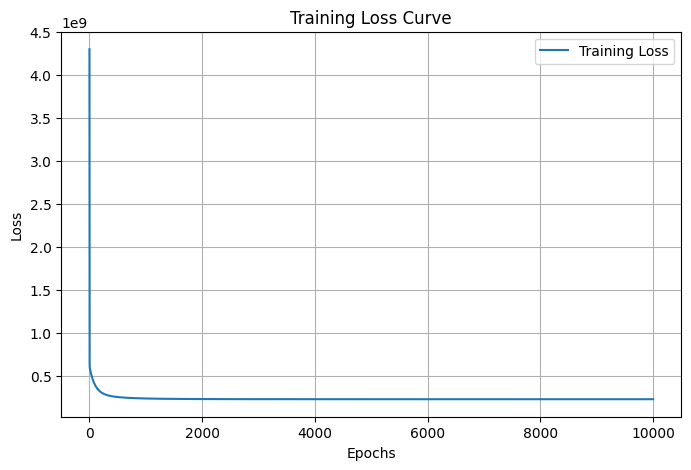

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Curve')
plt.legend()
plt.grid(True)
plt.show()

### **Testing with test data**

Load and apply all the preprocessing steps used in the training data for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

To load test data from GitHub, use the code below.


In [21]:
df_test = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv')

# Find all columns that are missing in the test set
missing_cols = set(df.columns) - set(df_test.columns)

# Add these columns to the test set with all zeros
for col in missing_cols:
    if col != 'SalePrice':
        df_test[col] = 0

if 'Utilities_AllPub' not in df_test.columns:
    df_test = df_test.join(pd.get_dummies(df_test['Utilities'], dtype = 'int32', prefix = 'Utilities'))
    df_test = df_test.drop('Utilities', axis = 1)

print("Loaded test set successfully. Columns:", df_test.columns.tolist())
df_test.head()

Loaded test set successfully. Columns: ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond', 'Utilities', 'SalePrice', 'Utilities_NoSeWa', 'Utilities_AllPub']


,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice,Utilities_NoSeWa,Utilities_AllPub
0,15623,2396,4476,813,555,5,AllPub,745000,0,0
1,11952,808,1969,534,0,6,AllPub,190000,0,0
2,7558,896,1913,342,0,6,AllPub,177000,0,0
3,6762,1187,1208,632,0,5,AllPub,206000,0,0
4,8529,1454,1434,527,0,5,AllPub,189000,0,0


Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

In [22]:
# Scale the features using scaling_params from training
for col in features_to_scale:
    col_min = scaling_params[col]['min']
    col_max = scaling_params[col]['max']
    df_test[col] = (df_test[col] - col_min) / (col_max - col_min)

# Fill NaN values
df_test.fillna(0, inplace=True)

# Keep only the features that were present in the training set (matching the training columns order)
train_cols_without_target = [col for col in df.columns if col != 'SalePrice']
df_test_aligned = df_test[train_cols_without_target]

# Convert to numpy array
x_test = df_test_aligned.to_numpy()
y_test = df_test['SalePrice'].to_numpy().reshape(-1, 1)

print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_test shape: (146, 8)
y_test shape: (146, 1)


In [ ]:
extra_cols = list(set(df_test.columns) - set(df.columns))
print("Extra columns in df_test:", extra_cols)

missing_cols = list(set(df.columns) - set(df_test.columns))
print("Missing columns in df_test:", missing_cols)

In [27]:
# Make predictions
y_pred_test = x_test @ w.T + b

# Compute test loss
loss_test = mse_loss_fn(y_test, y_pred_test)

print("Test set MSE Loss:", loss_test)

Test set MSE Loss: 2980549129.9164042


In [28]:
idx = np.random.randint(0, x_test.shape[0], 5)

# Extract sample predictions and ground truths
y_pred_test_sample = y_pred_test[idx].round().astype(int)
y_true_test_sample = y_test[idx].round().astype(int)

print('Predicted SalePrice: \t', y_pred_test_sample.squeeze().tolist())
print('Actual SalePrice: \t', y_true_test_sample.squeeze().tolist())
print('\nTest Loss: \t\t', loss_test)

Predicted SalePrice: 	 [174454, 130734, 188086, 111995, 146183]
Actual SalePrice: 	 [157900, 121600, 196500, 85000, 170000]

Test Loss: 		 2980549129.9164042
